In [7]:
%pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Kode 2.1 Pemisahan kanal dan Kontras Bercak 

In [8]:
from pathlib import Path
import sys

root = Path.cwd()
if not (root / "src" / "utils_cv.py").exists():
    root = root.parent

sys.path.insert(0, str(root / "src"))


KB kanal B   : 2.30
KB kanal G   : 0.45
KB kanal R   : 7.39
KB kanal Gray: 2.72
KB kanal H   : 6.68
KB kanal S   : 1.77
KB kanal V   : 1.03


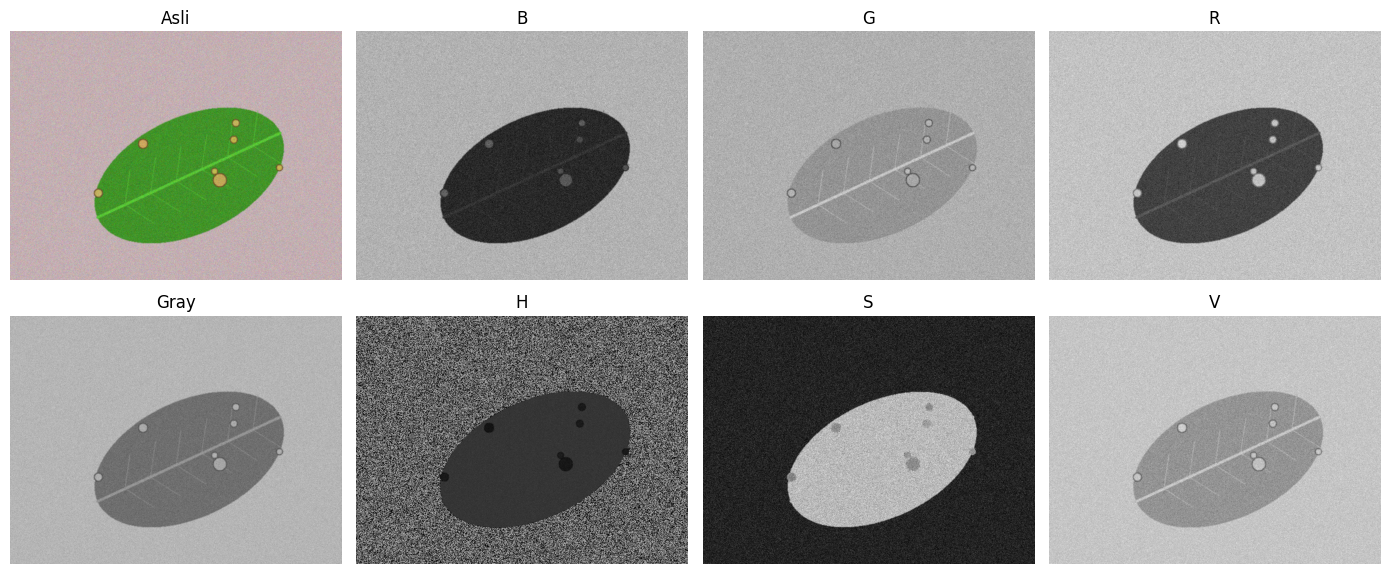

In [9]:
import cv2
from utils_cv import baca, tampil, kontras_bercak
  
nama = "teh_041.png"                 # kelas berat, kondisi normal 
img = baca(f"../data/sintetis/citra/{nama}") 
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0) 
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0) 
  
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) 
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) 
b, g, r = cv2.split(img) 
h, s, v = cv2.split(hsv) 
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v} 
  
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), 
       baris=2, ukuran=(14, 6)) 
for nm, c in kanal.items(): 
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}") 

# Kode 2.4 Sampling dan kuantisasi

In [10]:
import numpy as np
# sampling: perkecil lalu perbesar kembali ke ukuran semula 
for fx in [0.5, 0.2, 0.1, 0.05]: 
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA) 
    besar = cv2.resize(kecil, gray.shape[::-1], 
                       interpolation=cv2.INTER_NEAREST) 
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}") 
  
  
# kuantisasi: sisakan k bit 
for k in [1, 2, 3, 4, 8]: 
    langkah = 256 // (2 ** k) 
    kuant = (gray // langkah) * langkah 
    print(f"k={k}: {len(np.unique(kuant))} level, " 
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=3.60
fx=0.2: ukuran (96, 128), KB=3.65
fx=0.1: ukuran (48, 64), KB=2.59
fx=0.05: ukuran (24, 32), KB=1.17
k=1: 2 level, KB=2.34
k=2: 3 level, KB=2.36
k=3: 5 level, KB=3.00
k=4: 10 level, KB=2.48
k=8: 149 level, KB=2.72


# Kode 2.3 Rerata KB per kanal dan per kondisi

In [11]:
import cv2
import pandas as pd
from utils_cv import baca, kontras_bercak
  
def semua_kanal(img): 
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) 
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv) 
    return {"B": b, "G": g, "R": r, 
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 
            "H": h, "S": s, "V": v} 
  
label = pd.read_csv("../data/sintetis/label.csv") 
baris = [] 
for _, d in label[label.kelas == "berat"].iterrows(): 
    im = baca(f"../data/sintetis/citra/{d.nama_file}") 
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0) 
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)
tabel_kb = (pd.DataFrame(baris).groupby("kondisi").mean().round(2)
            .reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"]))
print(tabel_kb) 
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv") 

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          1.53  0.75   8.38  3.76  6.59  0.99  1.93
gelap           1.27  1.70  10.29  4.77  5.53  0.90  3.33
terang          2.53  0.19   7.57  3.62  6.68  1.73  1.38
kontras_rendah  0.92  0.55   3.90  2.25  1.91  0.22  1.54
bayangan        1.10  0.49   6.29  1.97  5.75  0.75  1.18


# Kode 2.6 Rerata KB kelas ringan


In [12]:
# Kelas ringan (teh_021 sampai teh_040), menggunakan metrik yang sama.
baris_ringan = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    md_l = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb_l = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb_l = {k: kontras_bercak(c, md_l, mb_l) for k, c in semua_kanal(im).items()}
    kb_l["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb_l)
tabel_kb_ringan = (pd.DataFrame(baris_ringan).groupby("kondisi").mean().round(2)
                   .reindex(["normal", "gelap", "terang", "kontras_rendah", "bayangan"]))
print(tabel_kb_ringan)


                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.09  0.69  7.93  3.35  6.42  0.80  1.69
gelap           0.64  0.58  8.00  2.07  6.35  1.02  0.96
terang          1.77  0.83  6.51  2.35  6.46  1.68  0.59
kontras_rendah  0.46  0.19  2.49  1.33  0.82  0.10  1.02
bayangan        0.57  0.69  4.79  0.84  6.52  1.35  0.75
